# Multilayer Perceptron (MLP)

In [1]:
import tensorflow as tf 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd


I0000 00:00:1776994348.122194   47427 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1776994348.902276   47427 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1776994352.023965   47427 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:

# loading tips dataset 
tips_data = sns.load_dataset('tips')

# Preprocessing the data

# s to numerical
tips_data = pd.get_dummies(tips_data, drop_first=True)

X = tips_data.drop('tip', axis=1)
y = tips_data['tip']

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Standardizing the features
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)


# Building the model for regression
model = tf.keras.Sequential([
       tf.keras.layers.Dense(64 , activation = 'relu' , input_shape =( X_train.shape[1] ,)),

       tf.keras.layers.Dense(32, activation = 'relu'),

       tf.keras.layers.Dense(1 )

])

# Compiling the model 

model.compile(optimizer = 'adam' ,
              loss = 'mean_squared_error' ,
              metrics  = ['mae'])


# Training the model 
model.fit(X_train , y_train , epochs = 50 , batch_size = 32 , verbose = 1 )

# Evaluating the model 

loss = model.evaluate(X_test , y_test , verbose = 0 )

print(f"Mean squared error: {loss[0]}")
print(f"Mean absolute error: {loss[1]}")

/home/saagar101/tf_env/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1776994357.921719   47427 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1776994357.928344   47427 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1776994358.322237   47427 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5174 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5050 Lapt

Epoch 1/50


I0000 00:00:1776994361.456555   47669 service.cc:153] XLA service 0x76dc48043eb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776994361.456604   47669 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5050 Laptop GPU, Compute Capability 12.0a (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.0)
I0000 00:00:1776994361.511943   47669 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1776994361.716157   47669 cuda_dnn.cc:461] Loaded cuDNN version 92100
I0000 00:00:1776994361.735452   47669 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1256__.9


1/7 ━━━━━━━━━━━━━━━━━━━━ 30s 5s/step - loss: 14.0864 - mae: 3.4971

I0000 00:00:1776994365.653612   47669 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1776994365.856805   47668 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1256__.9


7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 666ms/step - loss: 13.1331 - mae: 3.2892
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 10.1791 - mae: 2.8400
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.8552 - mae: 2.4383
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 6.0607 - mae: 2.0554 
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.5296 - mae: 1.7132 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.3502 - mae: 1.3923
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2.4581 - mae: 1.1602
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.8954 - mae: 0.9903
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.6030 - mae: 0.9279
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.4500 - mae: 0.8998
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.3519 - mae: 0.8856
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.3049 - mae: 0.8713
Epoch 13/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.2536 - ma

/home/saagar101/tf_env/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1776994377.819819   47669 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4668__.7
I0000 00:00:1776994379.414904   47670 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4668__.7


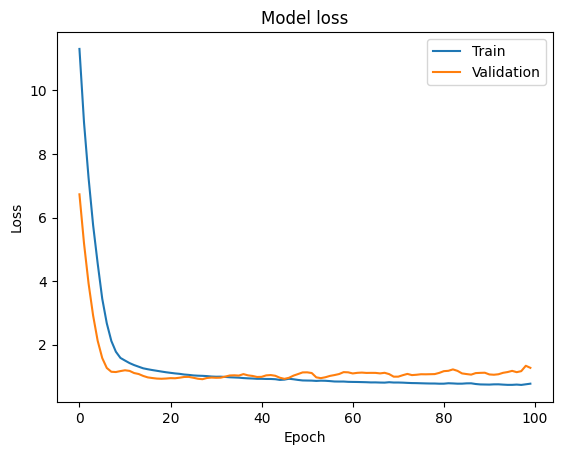

In [3]:
# Building the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)), # Input layer
    tf.keras.layers.Dense(32, activation='relu'), # Hidden layer
    tf.keras.layers.Dense(1)  # Output layer for regression
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# train the model and plot the training and testing loss and accuracy at each epoc
history = model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0, validation_data=(X_test, y_test))

# Evaluating the model (using Mean Squared Error)
loss = model.evaluate(X_test, y_test, verbose=0)
loss

# Plotting the training and testing loss
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

##  Model Loss Interpretation

- The training starts with a **high loss**, which quickly decreases in the first few epochs.  
  → This shows the model is learning important patterns early.

- After around **10–20 epochs**, both training and validation loss **stabilize**.  
  → Learning becomes slower and improvements are small.

- The **training loss and validation loss are very close** throughout training.  
  → This indicates **good generalization** (no strong overfitting).

- In later epochs, training loss slightly decreases, but **validation loss remains almost constant**.  
  → This means additional training is not improving performance on unseen data.

---

##  Optimal Number of Epochs

- The model reaches near-optimal performance around **20–30 epochs**.
- Training beyond this point gives **very little improvement**.
- So, **~25 epochs** are enough for this dataset.

---

##  Final Conclusion

- The model is well-trained and not overfitting.
- Early stopping around **25 epochs** would save time and give similar performance.


---
---
---

# Stopping the training using callbacks 

Epoch 1/100


/home/saagar101/tf_env/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1776994397.111472   47666 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_10197__.7


1/7 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - loss: 9.4565

I0000 00:00:1776994397.999187   47669 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_10197__.7


7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - loss: 9.1127 - val_loss: 5.1002
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 155ms/step - loss: 6.8003 - val_loss: 3.4920
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 4.9072 - val_loss: 2.2438
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 3.4104 - val_loss: 1.3884
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.3387 - val_loss: 0.9821
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.7246 - val_loss: 0.9119
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.4976 - val_loss: 1.0630
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.3959 - val_loss: 1.1728
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.3606 - val_loss: 1.1512
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 1.2890 - val_loss: 1.0872
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 1.2240 - val_loss: 1.0033


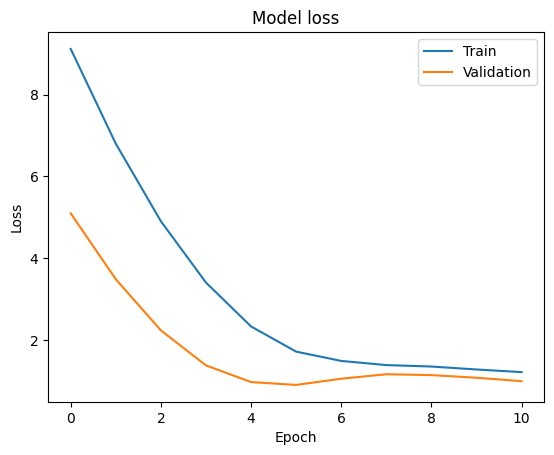

In [4]:
from tensorflow.keras.callbacks import EarlyStopping 


model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)), # Input layer
    tf.keras.layers.Dense(32, activation='relu'), # Hidden layer
    tf.keras.layers.Dense(1)  # Output layer for regression
])

model.compile(optimizer = 'adam' , loss = 'mean_squared_error')


early_stopping = EarlyStopping(patience=5)    # patience is the number of epochs with no improvement after which training will be stopped

history = model.fit(X_train , y_train , epochs= 100  , batch_size=32 , verbose = 1 , validation_data = (X_test , y_test) , 
                    callbacks = [early_stopping])

loss = model.evaluate(X_test , y_test , verbose = 0)

loss

import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()